# FracAtlas: bone fracture classification and localization

Final models:

| Task | Model | Weights |
|---|---|---|
| Classification (fractured / normal) | YOLOv8m-cls, imgsz 512, threshold 0.0050 | `runs/classify/fracatlas_yolov8m_cls_512/weights/best.pt` |
| Detection (where is the fracture) | YOLOv8n, imgsz 640 | `runs/detect/fracatlas_yolov8n/weights/best.pt` |

**This notebook does not retrain.** The training code is shown exactly as it was used, behind a
`TRAIN = False` switch. All results below are loaded from the files saved when the models were trained
and evaluated.

Rules followed: train images for learning only; val images for choosing the epoch, the model and the
threshold; test images used once for the final score, never for training or tuning.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
CLS_RUN = ROOT / "runs" / "classify" / "fracatlas_yolov8m_cls_512"
DET_RUN = ROOT / "runs" / "detect" / "fracatlas_yolov8n"
TRAIN = False   # keep False: True would retrain from scratch (about 1.5-3 h per model on an RTX 3050 4 GB)

pd.set_option("display.precision", 4)
print("Project folder:", ROOT)
print("Classifier run found:", CLS_RUN.exists(), "| Detector run found:", DET_RUN.exists())

Project folder: C:\Users\bikas\Downloads\FracAtlas
Classifier run found: True | Detector run found: True


## 1. Dataset

All three folders contain the same FracAtlas images and the same train / val / test split, arranged for
each task:

- `datasets/cls`: `fractured/` and `non_fractured/` folders (classifier val and test).
- `datasets/cls_os`: the same, with train fractured images copied 3x to balance the classes (classifier
  training). It has no test folder.
- `datasets/det`: images plus YOLO box labels (detector).

In [2]:
rows = []
for split in ("train", "val", "test"):
    fr = len(list((ROOT / "datasets/cls" / split / "fractured").glob("*.jpg")))
    nf = len(list((ROOT / "datasets/cls" / split / "non_fractured").glob("*.jpg")))
    os_fr = len(list((ROOT / "datasets/cls_os" / split / "fractured").glob("*.jpg"))) if split != "test" else None
    labels = list((ROOT / "datasets/det/labels" / split).glob("*.txt"))
    boxes = sum(len([l for l in p.read_text().splitlines() if l.strip()]) for p in labels)
    rows.append(dict(split=split, fractured=fr, normal=nf, total=fr + nf,
                     fractured_in_cls_os=os_fr, fracture_boxes_det=boxes))
pd.DataFrame(rows).set_index("split")

,fractured,normal,total,fractured_in_cls_os,fracture_boxes_det
split,,,,,
train,574,2617,3191,1722.0,764
val,82,374,456,82.0,91
test,63,282,345,NaN,69


## 2. Classification: training code

This is the training call from `train_classify.py` with the settings of the final run.

In [3]:
from ultralytics import YOLO

cls_args = dict(
    data=str(ROOT / "datasets" / "cls_os"),   # train (fractured x3) + val; no test folder
    epochs=100, patience=20, imgsz=512, batch=8,
    workers=4, device=0, seed=42,
    project=str(ROOT / "runs" / "classify"), name="fracatlas_yolov8m_cls_512", exist_ok=True,
)

if TRAIN:
    model = YOLO("yolov8m-cls.pt")            # ImageNet-pretrained YOLOv8 medium classifier
    model.train(**cls_args)
else:
    print("TRAIN = False -> training skipped, using the saved run:", CLS_RUN.name)
    print("Settings used:", {k: v for k, v in cls_args.items() if k not in ("project", "data")})

TRAIN = False -> training skipped, using the saved run: fracatlas_yolov8m_cls_512
Settings used: {'epochs': 100, 'patience': 20, 'imgsz': 512, 'batch': 8, 'workers': 4, 'device': 0, 'seed': 42, 'name': 'fracatlas_yolov8m_cls_512', 'exist_ok': True}


## 3. Classification: training log (saved `results.csv`)

In [4]:
cls_hist = pd.read_csv(CLS_RUN / "results.csv")
cls_hist.columns = cls_hist.columns.str.strip()
best = cls_hist.loc[cls_hist["metrics/accuracy_top1"].idxmax()]
print(f"Epochs run: {len(cls_hist)} of 100 (early stopping, patience 20)")
print(f"Best epoch: {int(best['epoch'])}  val top-1 accuracy {best['metrics/accuracy_top1']:.4f}  (saved as best.pt)")
cls_hist[["epoch", "train/loss", "val/loss", "metrics/accuracy_top1"]].iloc[::10]

Epochs run: 94 of 100 (early stopping, patience 20)
Best epoch: 74  val top-1 accuracy 0.9320  (saved as best.pt)


,epoch,train/loss,val/loss,metrics/accuracy_top1
0,1,0.5398,0.4855,0.7873
10,11,0.3480,0.3401,0.8553
20,21,0.2595,0.2877,0.9123
30,31,0.1816,0.3417,0.9123
40,41,0.1494,0.4171,0.9123
50,51,0.1016,0.3640,0.9211
60,61,0.0960,0.4099,0.9057
70,71,0.0676,0.4151,0.9211
80,81,0.0507,0.4714,0.9145
90,91,0.0451,0.5941,0.9189


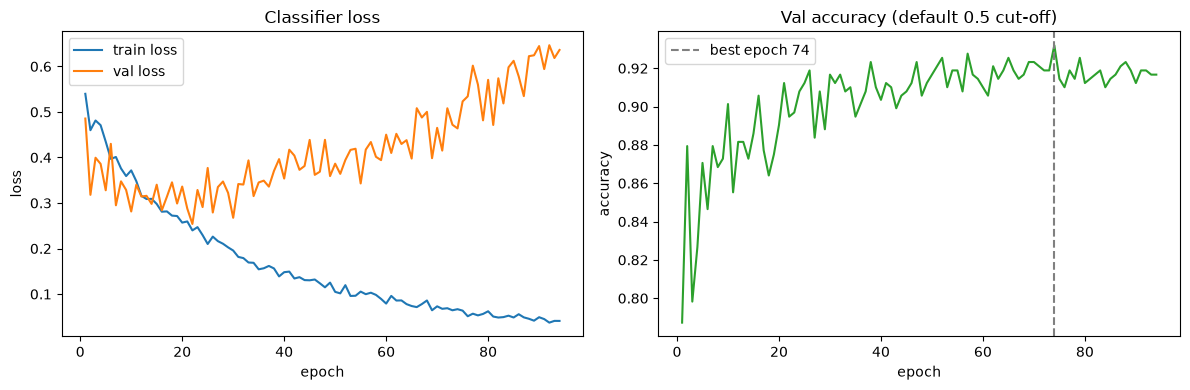

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(cls_hist["epoch"], cls_hist["train/loss"], label="train loss")
ax[0].plot(cls_hist["epoch"], cls_hist["val/loss"], label="val loss")
ax[0].set(title="Classifier loss", xlabel="epoch", ylabel="loss"); ax[0].legend()
ax[1].plot(cls_hist["epoch"], cls_hist["metrics/accuracy_top1"], color="tab:green")
ax[1].axvline(best["epoch"], ls="--", color="gray", label=f"best epoch {int(best['epoch'])}")
ax[1].set(title="Val accuracy (default 0.5 cut-off)", xlabel="epoch", ylabel="accuracy"); ax[1].legend()
plt.tight_layout(); plt.show()

## 4. Classification: threshold chosen on VAL only

The model outputs P(fractured). The default 0.5 cut-off misses many fractures, so the threshold was chosen
on the val set: the highest threshold that still finds at least 80% of val fractures. That gives 0.0050.
These are the saved val results.

In [6]:
val = json.loads((CLS_RUN / "val_threshold.json").read_text())
opts = [("default 0.5", val["val_argmax"]), ("85% recall target", val["val_tuned_085"]),
        ("80% recall target (CHOSEN)", val["val_tuned"])]
pd.DataFrame([{"option": n, "threshold": m["threshold"], "val accuracy": m["accuracy"], "val recall": m["recall"],
               "val precision": m["precision"], "val F1": m["f1"], "missed (FN)": m["fn"], "false alarms (FP)": m["fp"]}
              for n, m in opts]).set_index("option")

,threshold,val accuracy,val recall,val precision,val F1,missed (FN),false alarms (FP)
option,,,,,,,
default 0.5,0.5000,0.9320,0.6707,0.9322,0.7801,27,4
85% recall target,0.0018,0.7982,0.8537,0.4667,0.6034,12,80
80% recall target (CHOSEN),0.0050,0.8575,0.8049,0.5739,0.6701,16,49


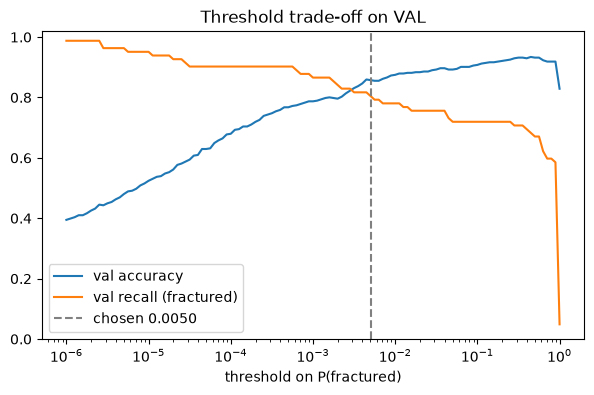

In [7]:
# Accuracy and recall on VAL for every threshold (from the saved val probabilities; no test data)
from clf import metrics

names = list(val["val_probs"])
y = [val["val_labels"][n] for n in names]
p = [val["val_probs"][n] for n in names]
grid = [10 ** (e / 20) for e in range(-120, 1)]          # 1e-6 ... 1
curve = pd.DataFrame([metrics(y, p, t) for t in grid])
plt.figure(figsize=(7, 4))
plt.semilogx(curve["threshold"], curve["accuracy"], label="val accuracy")
plt.semilogx(curve["threshold"], curve["recall"], label="val recall (fractured)")
plt.axvline(val["val_tuned"]["threshold"], ls="--", color="gray", label="chosen 0.0050")
plt.xlabel("threshold on P(fractured)"); plt.ylim(0, 1.02); plt.legend(); plt.title("Threshold trade-off on VAL")
plt.show()

## 5. Classification: final results (train / val / test)

Test was evaluated once with the threshold fixed on val. Val numbers are slightly optimistic because the
model and threshold were chosen on val; **the test numbers are the honest result.**

In [8]:
res = json.loads((CLS_RUN / "test_results.json").read_text())
splits = {"Train": res["train"], "Val": val["val_tuned"], "Test": res["test"]}
table = pd.DataFrame({k: {"accuracy": m["accuracy"], "recall (fractured)": m["recall"],
                          "precision": m["precision"], "F1": m["f1"],
                          "TP": m["tp"], "FN": m["fn"], "FP": m["fp"], "TN": m["tn"]}
                      for k, m in splits.items()})
table

,Train,Val,Test
accuracy,0.9596,0.8575,0.8725
recall (fractured),1.0000,0.8049,0.8413
precision,0.8165,0.5739,0.6092
F1,0.8990,0.6701,0.7067
TP,574.0000,66.0000,53.0000
FN,0.0000,16.0000,10.0000
FP,129.0000,49.0000,34.0000
TN,2488.0000,325.0000,248.0000


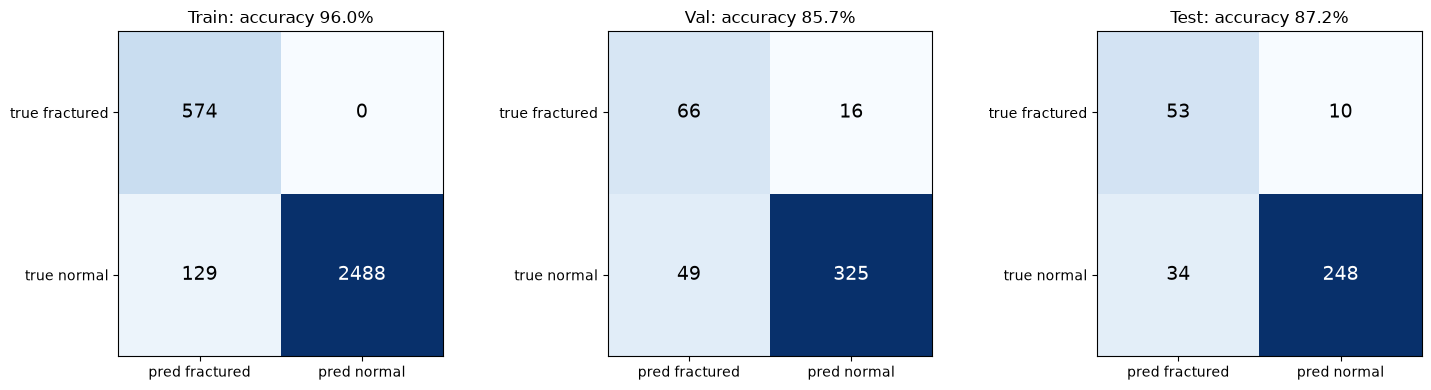

TEST  accuracy 87.2% | recall 84.1% | precision 60.9% | F1 0.707 | 53 found, 10 missed, 34 false alarms, 248 correct normals


In [9]:
def plot_cm(m, title, ax):
    cm = [[m["tp"], m["fn"]], [m["fp"], m["tn"]]]
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i][j], ha="center", va="center", fontsize=14,
                    color="white" if cm[i][j] > max(map(max, cm)) / 2 else "black")
    ax.set_xticks([0, 1], ["pred fractured", "pred normal"]); ax.set_yticks([0, 1], ["true fractured", "true normal"])
    ax.set_title(title)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (k, m) in zip(ax, splits.items()):
    plot_cm(m, f"{k}: accuracy {m['accuracy']:.1%}", a)
plt.tight_layout(); plt.show()

t = res["test"]
print(f"TEST  accuracy {t['accuracy']:.1%} | recall {t['recall']:.1%} | precision {t['precision']:.1%} | "
      f"F1 {t['f1']:.3f} | {t['tp']} found, {t['fn']} missed, {t['fp']} false alarms, {t['tn']} correct normals")

## 6. Detection: training code

This is the training call from `train_detect.py` with the settings of the chosen run.

In [10]:
det_args = dict(
    data=str(ROOT / "datasets" / "det" / "data.yaml"),  # images + YOLO box labels, one class "fractured"
    epochs=100, patience=25, imgsz=640, batch=16,
    workers=4, device=0, seed=42,
    project=str(ROOT / "runs" / "detect"), name="fracatlas_yolov8n", exist_ok=True,
)

if TRAIN:
    det_model = YOLO("yolov8n.pt")            # COCO-pretrained YOLOv8 nano detector
    det_model.train(**det_args)
else:
    print("TRAIN = False -> training skipped, using the saved run:", DET_RUN.name)
    print("Settings used:", {k: v for k, v in det_args.items() if k not in ("project", "data")})

TRAIN = False -> training skipped, using the saved run: fracatlas_yolov8n
Settings used: {'epochs': 100, 'patience': 25, 'imgsz': 640, 'batch': 16, 'workers': 4, 'device': 0, 'seed': 42, 'name': 'fracatlas_yolov8n', 'exist_ok': True}


## 7. Detection: training log (saved `results.csv`)

Epochs run: 100 of 100 | best val mAP50 0.492 at epoch 94


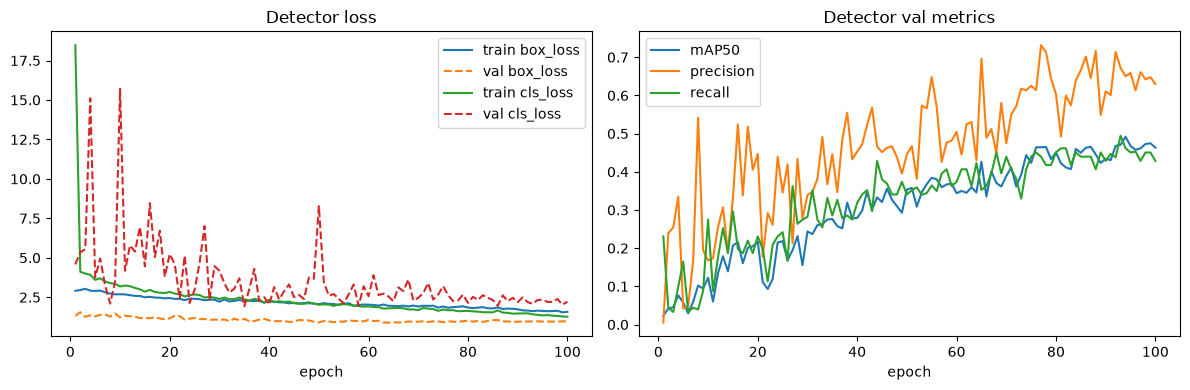

In [11]:
det_hist = pd.read_csv(DET_RUN / "results.csv")
det_hist.columns = det_hist.columns.str.strip()
dbest = det_hist.loc[det_hist["metrics/mAP50(B)"].idxmax()]
print(f"Epochs run: {len(det_hist)} of 100 | best val mAP50 {dbest['metrics/mAP50(B)']:.3f} at epoch {int(dbest['epoch'])}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for c in ("box_loss", "cls_loss"):
    ax[0].plot(det_hist["epoch"], det_hist[f"train/{c}"], label=f"train {c}")
    ax[0].plot(det_hist["epoch"], det_hist[f"val/{c}"], ls="--", label=f"val {c}")
ax[0].set(title="Detector loss", xlabel="epoch"); ax[0].legend()
for c, lab in (("metrics/mAP50(B)", "mAP50"), ("metrics/precision(B)", "precision"), ("metrics/recall(B)", "recall")):
    ax[1].plot(det_hist["epoch"], det_hist[c], label=lab)
ax[1].set(title="Detector val metrics", xlabel="epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

In [12]:
sel = ROOT / "runs" / "detect" / "detect_selection.json"
if sel.exists():
    print("Detector chosen on VAL mAP50 (all runs scored on the same cleaned val set):")
    print(json.dumps(json.loads(sel.read_text()), indent=2)[:1500])

Detector chosen on VAL mAP50 (all runs scored on the same cleaned val set):
{
  "criterion": "val mAP50 on cleaned val set",
  "val": {
    "fracatlas_yolov8n": {
      "map50": 0.49221589430865476,
      "map50_95": 0.20168020014633364,
      "precision": 0.6517710563868028,
      "recall": 0.46153846153846156
    },
    "detect_clean": {
      "map50": 0.45158266810199976,
      "map50_95": 0.21582916159347737,
      "precision": 0.6719112441852101,
      "recall": 0.3956043956043956
    },
    "detect_clean_s": {
      "map50": 0.41037832604835933,
      "map50_95": 0.17546919376343675,
      "precision": 0.5797045010237548,
      "recall": 0.42443222273431847
    }
  },
  "chosen": "fracatlas_yolov8n"
}


## 8. Detection: final test results (evaluated once)

In [13]:
dt = json.loads((DET_RUN / "test_results.json").read_text())
print(f"TEST  mAP50 {dt['map50']:.3f} | mAP50-95 {dt['map50_95']:.3f} | precision {dt['precision']:.3f} | recall {dt['recall']:.3f}")
pd.DataFrame([{"confidence": c, "boxes found (IoU>=0.5)": f"{b['found']} / {b['gt']}", "box recall": b["recall"],
               "wrong boxes": b["wrong"], "normal images with a false box": f"{b['normal_with_alarm']} / {b['normal_imgs']}"}
              for c, b in dt["by_conf"].items()]).set_index("confidence")

TEST  mAP50 0.419 | mAP50-95 0.169 | precision 0.560 | recall 0.405

,boxes found (IoU>=0.5),box recall,wrong boxes,normal images with a false box
confidence,,,,
0.25,26 / 69,0.3768,15,6 / 282
0.1,30 / 69,0.4348,34,14 / 282


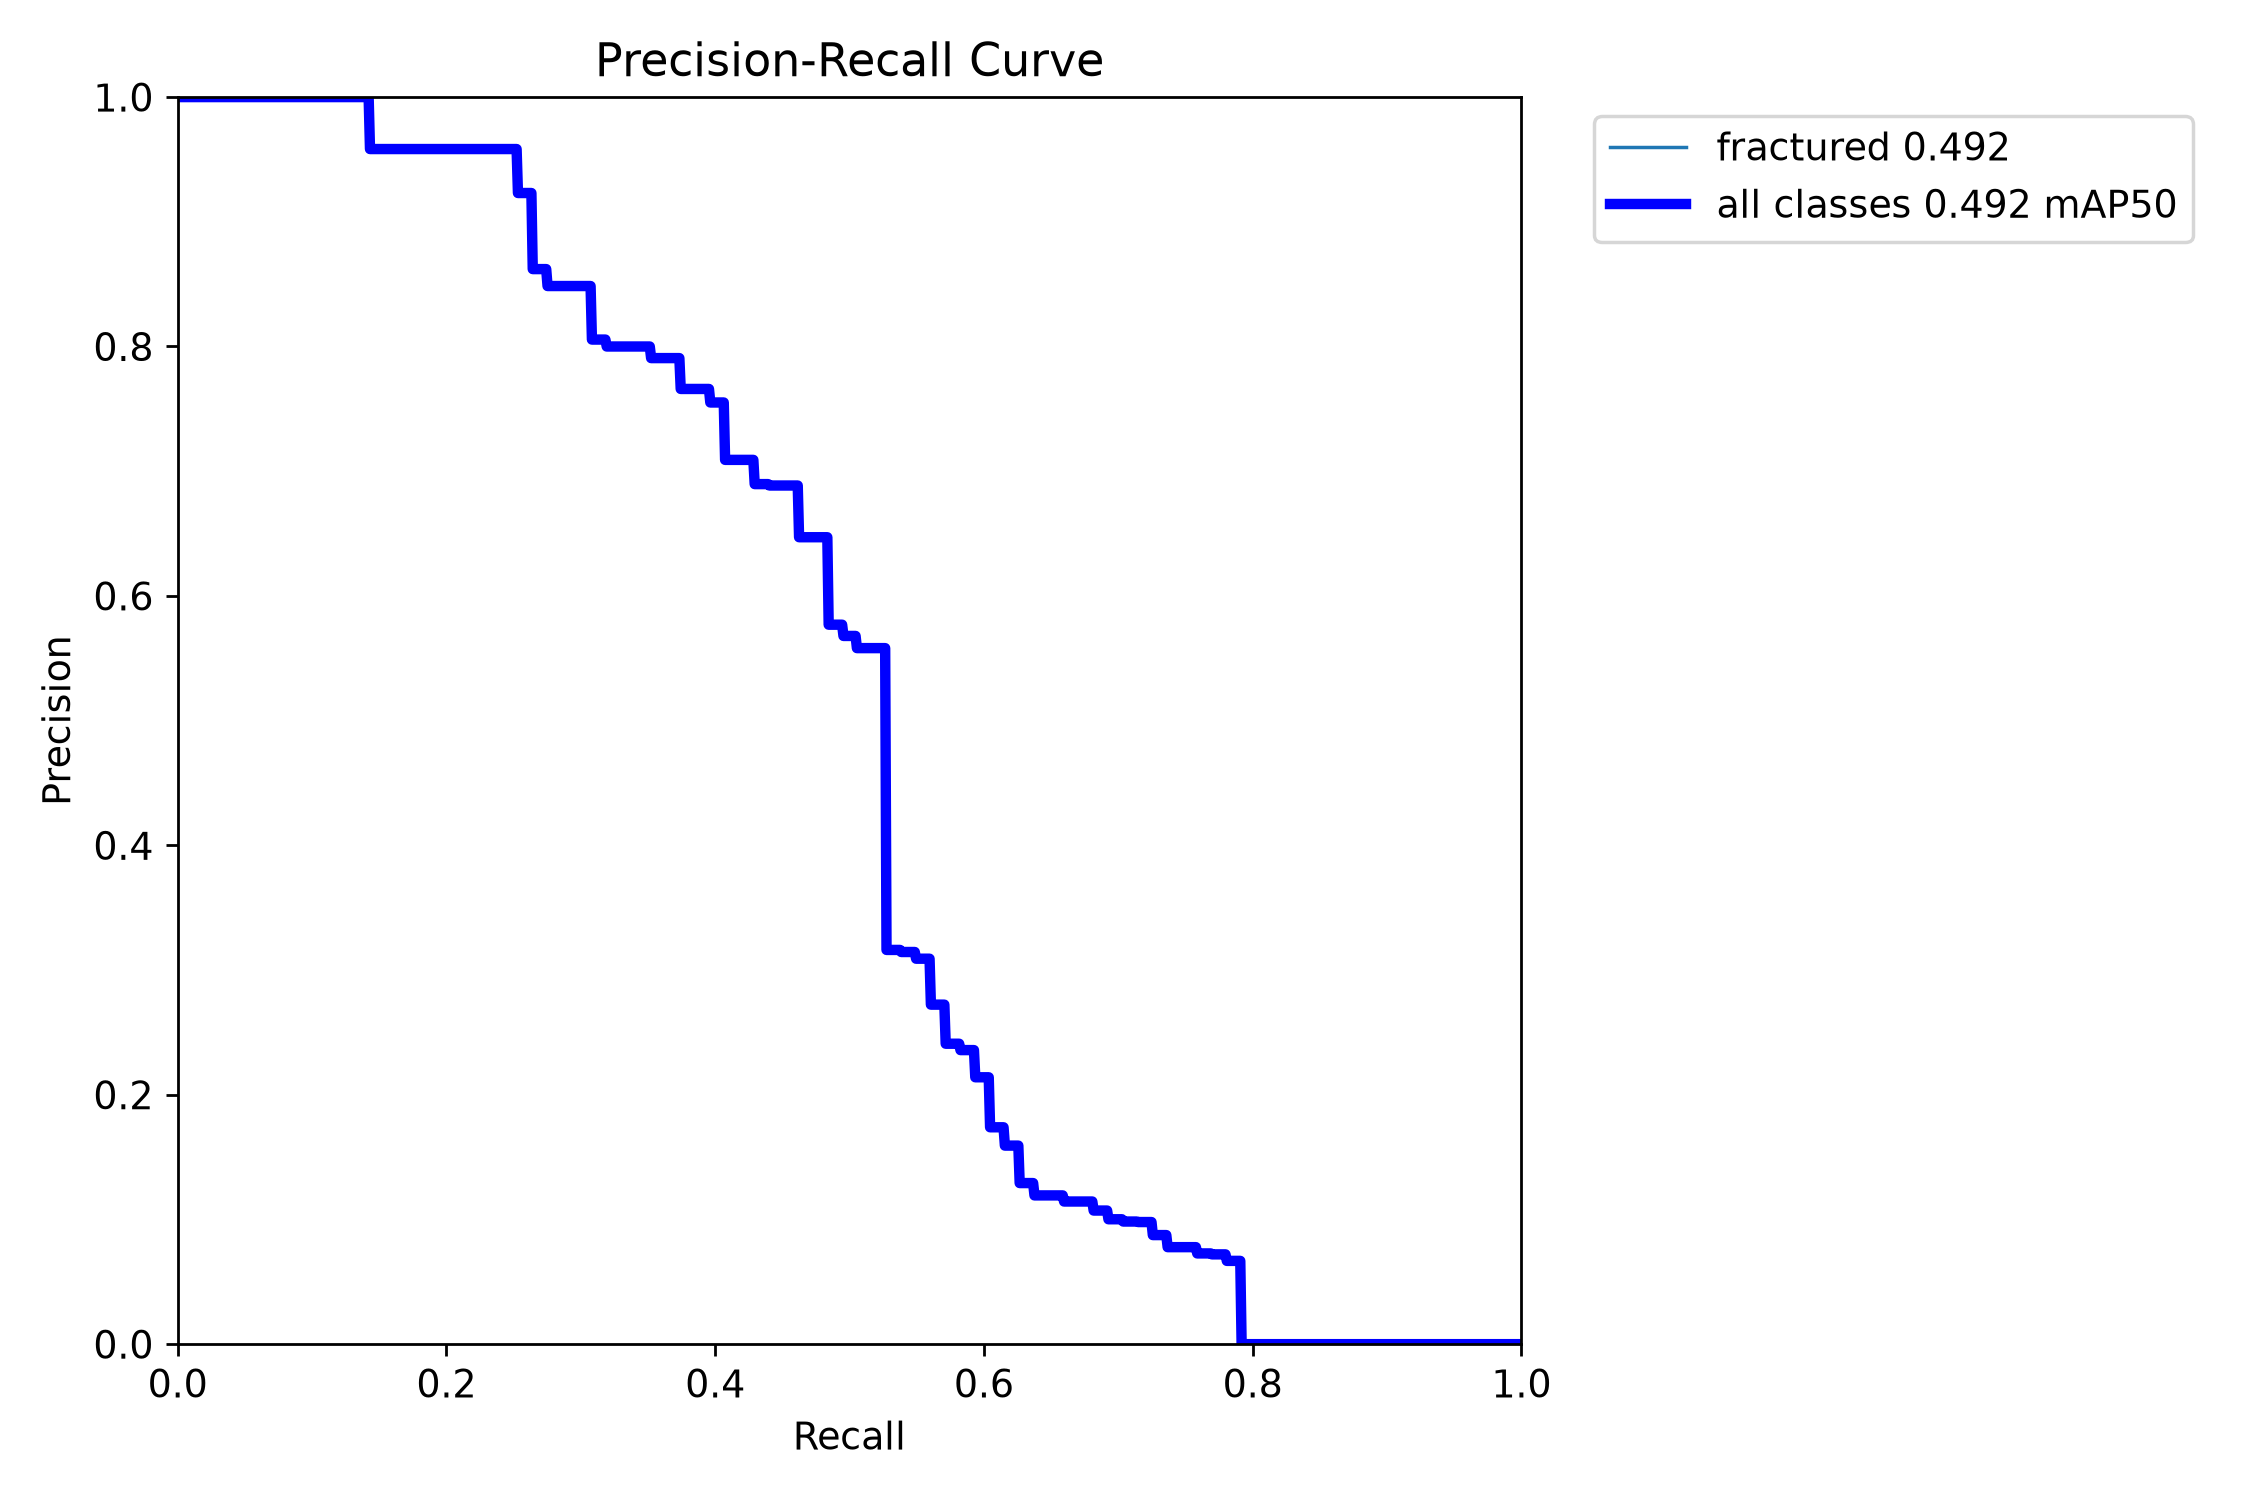

In [14]:
display(Image(filename=str(DET_RUN / "BoxPR_curve.png"), width=600))

## 9. Example predictions with the final models

This is inference only, to show what the models output; nothing is tuned here. The images are the same
three test images used for the README examples (2 fractured, 1 normal).

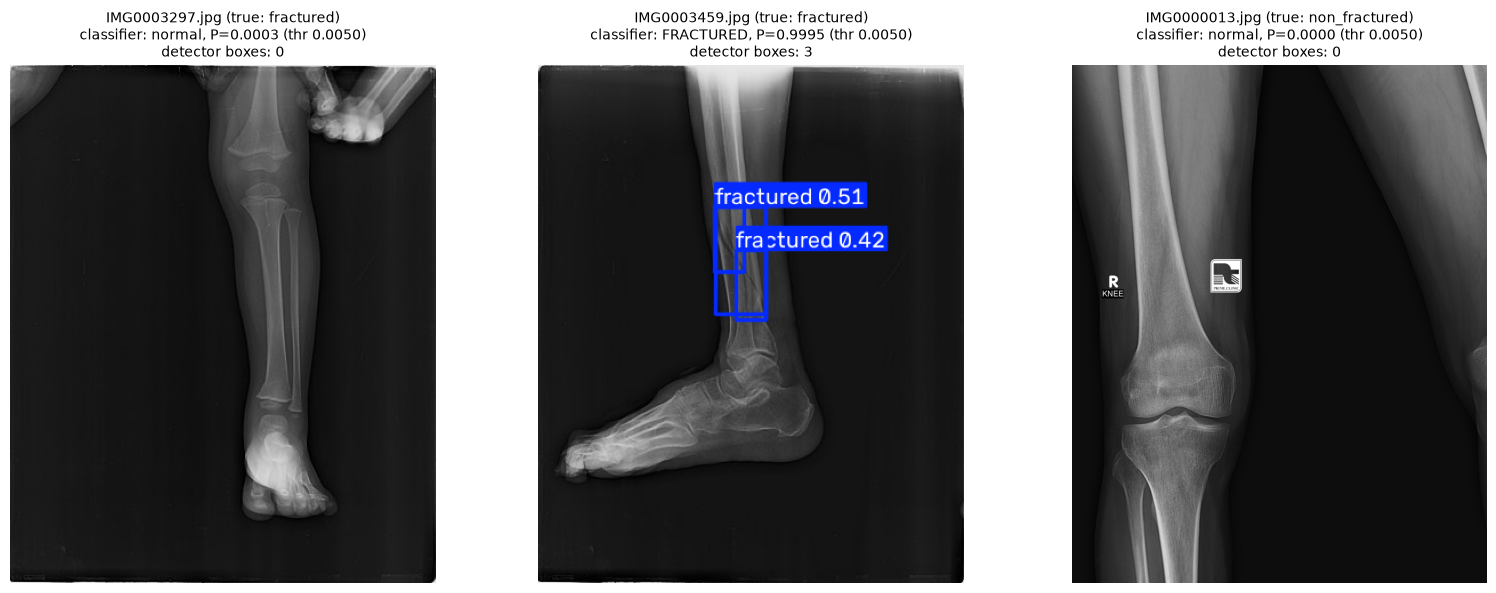

In [15]:
from clf import Classifier

cfg = json.loads((ROOT / "final_models" / "classifier_threshold.json").read_text())
thr = cfg["fractured_threshold"]
clf_model = Classifier(cfg["members"], base=ROOT / "final_models")
det_final = YOLO(str(ROOT / "final_models" / "detect_best.pt"))

fr = sorted((ROOT / "datasets/cls/test/fractured").glob("*.jpg"))
nf = sorted((ROOT / "datasets/cls/test/non_fractured").glob("*.jpg"))
examples = [fr[0], fr[len(fr) // 2], nf[0]]

fig, ax = plt.subplots(1, 3, figsize=(16, 6))
for a, path, prob in zip(ax, examples, clf_model.probs(examples)):
    r = det_final.predict(str(path), imgsz=640, conf=0.25, verbose=False)[0]
    pred = "FRACTURED" if prob >= thr else "normal"
    a.imshow(r.plot()[:, :, ::-1]); a.axis("off")
    a.set_title(f"{path.name} (true: {path.parent.name})\nclassifier: {pred}, P={prob:.4f} (thr {thr:.4f})\n"
                f"detector boxes: {len(r.boxes)}", fontsize=10)
plt.tight_layout(); plt.show()

## 10. Summary

| | Train | Val | Test |
|---|---|---|---|
| Classifier accuracy | 96.0% | 85.7% | **87.2%** |
| Fractured recall | 100% | 80.5% | **84.1%** |
| Precision | 81.7% | 57.4% | **60.9%** |
| F1 | 0.899 | 0.670 | **0.707** |

Detector on test: mAP50 **0.419**, precision 0.560, recall 0.405.

Val is slightly optimistic because the model and threshold were chosen on val; test is the honest result.

# 11. Improvement attempt (documented; its files were removed)

A regularised retrain of YOLOv8m-cls 512 was tried to reduce overfitting: AdamW lr 0.0005, cosine schedule
over 40 epochs, patience 15, weight decay 0.05, dropout 0.3, same data.

**Overfitting was fixed.** At the saved epoch (10), val loss minus train loss was -0.005, against 0.397 for
the old run. Lowest val loss: 0.224 (old: 0.254).

**Test accuracy did not improve.** On VAL (threshold set for 80.5% recall), old + new averaged scored
87.7% val accuracy against 85.7% for the current model. That passed the pre-set +1-point rule, so it was
tested once:

| | Current model (final) | Old + new average |
|---|---|---|
| Test accuracy | **87.2%** | 86.7% |
| Test recall | **84.1%** | 79.4% |
| Test precision | 60.9% | 60.2% |
| Test F1 | **0.707** | 0.685 |

The val gain (9 images out of 456) did not carry over to test, so **the current model stays final**. The
test set has been used for 3 models in total: the 512 model, the 640 attempt and this ensemble.